<a href="https://colab.research.google.com/github/AM0ya/Clase_Programacion/blob/main/Pr%C3%A1cticaRegresionDatosCategoricos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

** Regresión lineal con datos categóricos: Costos, Localidades y Salarios**

📌 Objetivos de la Práctica:
Al finalizar esta práctica, los estudiantes serán capaces de:

- Codificar variables categóricas usando one-hot encoding con K-1 para problemas de regresión
- Realizar AED
- Construir un modelo de regresión con variables dummy
- Interpretar los resultados de los coeficientes
- Analizar los resultados de los errores residuales
- Calcular el desempeño del modelo de regresión.

Problema: Se podría argumentar que el salario está relacionado con el costo de la educación. Por lo tanto, para analizar este argumentos veremos qué sucede cuando usamos las variables independientes cost y location.

# 1. Carga de datos

Carga el conjunto de datos college.csv, que está en campus virtual, en un dataframe. Elige de este conjunto las columnas salary (variable dependiente), cost(variable independiente - numérica) y location (variable independiente categórica).

Realiza lo siguiente:

*   Convierte si es necesario la variable location a tipo de dato categórico
*   Usa la instrucción describe() en las variables salary y cost
* Cuenta la cantidad de datos que hay por categoría en location
* Convierte la variable location usando one-hot encoding



In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import datasets
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from statsmodels.tools.tools import add_constant
from statsmodels.stats.outliers_influence import variance_inflation_factor

#carga de data set guardado en drive
from google.colab import drive
drive.mount('/content/drive')

df = pd.read_csv("/content/drive/MyDrive/Maestria/Programación/Semana 12/college.csv")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,id,name,salary,cost,public,location
0,1,Massachusetts Institute of Technology (MIT),119000,189300,Private,NE
1,2,Harvard University,121000,189600,Private,NE
2,3,Dartmouth College,123000,188400,Private,NE
3,4,Princeton University,123000,188700,Private,NE
4,5,Yale University,110000,194200,Private,NE


In [5]:
df_selected = df[['salary', 'cost', 'location']].copy()
df_selected['location'] = df_selected['location'].astype('category')

print("--- Estadísticas descriptivas de Salary y Cost ---")
display(df_selected[['salary', 'cost']].describe())

print("\n--- Cantidad de datos por categoría en Location ---")
display(df_selected['location'].value_counts())

--- Estadísticas descriptivas de Salary y Cost ---


,salary,cost
count,85.000000,85.000000
mean,95898.823529,142434.470588
std,11937.121912,53913.064578
min,74900.000000,18260.000000
25%,87100.000000,84670.000000
50%,93200.000000,169200.000000
75%,105000.000000,188700.000000
max,123000.000000,227300.000000



--- Cantidad de datos por categoría en Location ---


,count
location,
NE,25
W,21
S,20
MW,19


In [6]:
df_encoded = pd.get_dummies(df_selected, columns=['location'], drop_first=True, dtype=int)

print("--- Dataset final con One-Hot Encoding (K-1) ---")
display(df_encoded.head())

--- Dataset final con One-Hot Encoding (K-1) ---


,salary,cost,location_NE,location_S,location_W
0,119000,189300,1,0,0
1,121000,189600,1,0,0
2,123000,188400,1,0,0
3,123000,188700,1,0,0
4,110000,194200,1,0,0


# 2. Análisis Exploratorio de los Datos

Realiza un análisis exploratorio de los datos y discute lo que observas en cada gráfica.


*   Crea un histograma de la columna salary. Discute lo que observas
* Crea un diagrama de dispersión de salary vs cost, considerando lo siguiente: para cada punto elegirás un color que represente la localidad en la que está el salario y el costo de la educación. Por lo tanto el diagrama de dispersión debería tener puntos en 4 colores distintos. Discute lo que observas
* Emplea un boxplot para saber si hay diferencias en los costos según la ubicación, es decir, con boxplot deberás analizar la distribución de cost por localidad. Discute lo que observas




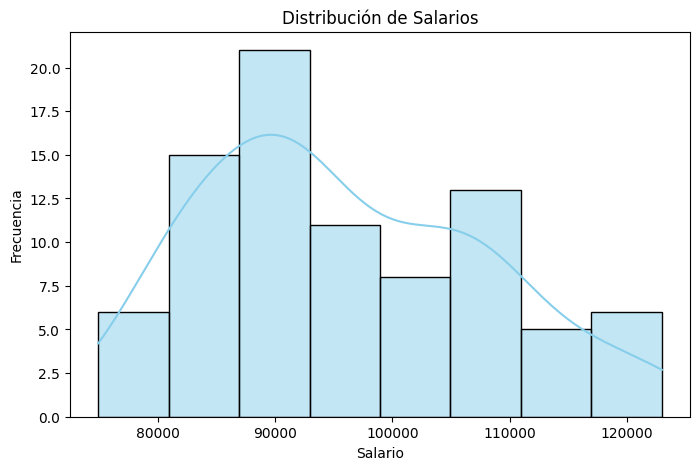

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Histograma de Salary
plt.figure(figsize=(8, 5))
sns.histplot(df_selected['salary'], kde=True, color='skyblue')
plt.title('Distribución de Salarios')
plt.xlabel('Salario')
plt.ylabel('Frecuencia')
plt.show()

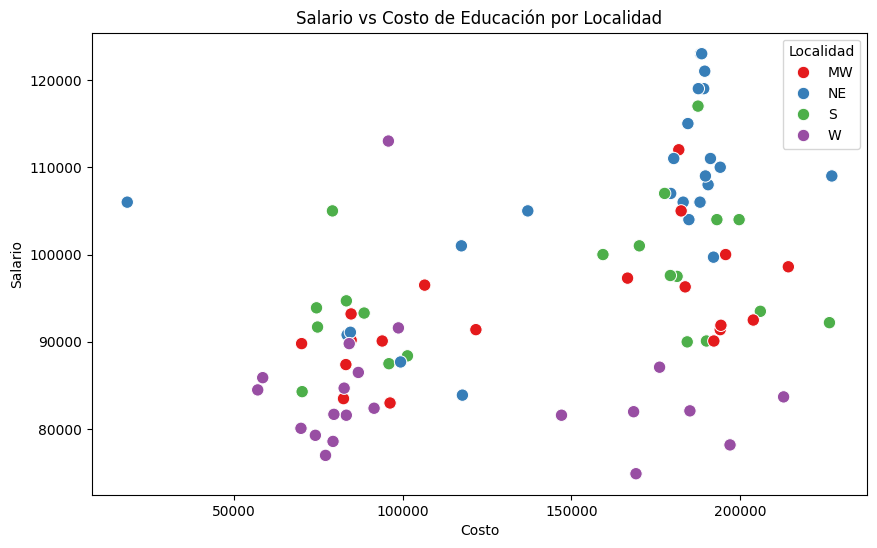

In [8]:
# 2. Diagrama de dispersión de Salary vs Cost coloreado por Location
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_selected, x='cost', y='salary', hue='location', palette='Set1', s=80)
plt.title('Salario vs Costo de Educación por Localidad')
plt.xlabel('Costo')
plt.ylabel('Salario')
plt.legend(title='Localidad')
plt.show()

/tmp/ipykernel_3304/2207554218.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_selected, x='location', y='cost', palette='Pastel1')


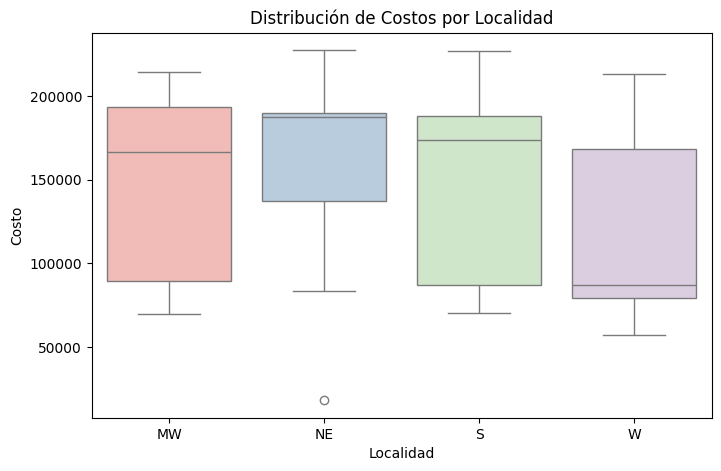

In [9]:
# 3. Boxplot de Cost por Localidad
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_selected, x='location', y='cost', palette='Pastel1')
plt.title('Distribución de Costos por Localidad')
plt.xlabel('Localidad')
plt.ylabel('Costo')
plt.show()

# 3. Construcción del modelo de regresión

- Construye el modelo de regresión usando los datos de salario, costo y location. Recuerda que esta última debe ser en su versión codificada con one-hot encoding.
- Imprime los coeficientes e interpreta qué significan cuando se sustituyen valores en costo, y location (versión codificada). Si no recuerdas cómo se hace esta interpretación consulta los videos.


In [10]:
import statsmodels.api as sm

# Definir variables independientes (X) y dependiente (y)
X = df_encoded[['cost', 'location_NE', 'location_S', 'location_W']]
X = sm.add_constant(X)  # Agregar intercepto
y = df_encoded['salary']

# Ajustar el modelo
modelo = sm.OLS(y, X).fit()

# Mostrar el resumen
print(modelo.summary())

                            OLS Regression Results                            
Dep. Variable:                 salary   R-squared:                       0.571
Model:                            OLS   Adj. R-squared:                  0.549
Method:                 Least Squares   F-statistic:                     26.57
Date:                Tue, 03 Nov 2026   Prob (F-statistic):           4.96e-14
Time:                        03:46:25   Log-Likelihood:                -882.12
No. Observations:                  85   AIC:                             1774.
Df Residuals:                      80   BIC:                             1786.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const        8.499e+04   3092.655     27.481      

# 4. Análisis de Residuos

- Construyen una visualización de predicciones (salario estimado) vs valores reales (salario real).
- Crea una gráfica de los errores residuales. Discute lo que observas

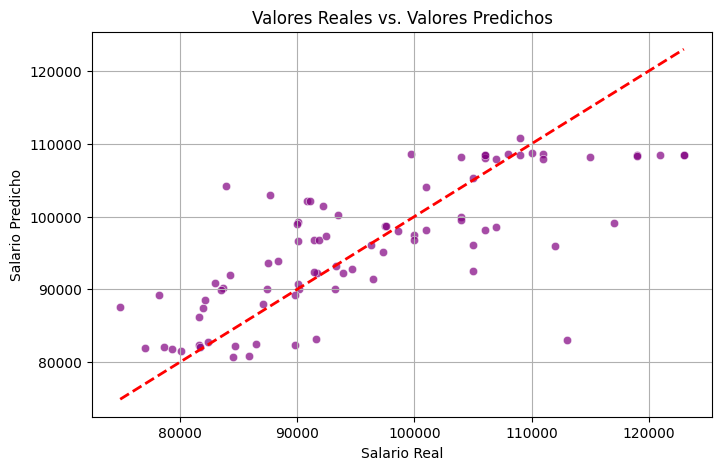

In [11]:
# Calcular valores predichos y residuos
y_pred = modelo.predict(X)
residuos = y - y_pred

# 1. Gráfica de Predicciones vs Valores Reales
plt.figure(figsize=(8, 5))
sns.scatterplot(x=y, y=y_pred, color='purple', alpha=0.7)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2)  # Línea de identidad
plt.title('Valores Reales vs. Valores Predichos')
plt.xlabel('Salario Real')
plt.ylabel('Salario Predicho')
plt.grid(True)
plt.show()

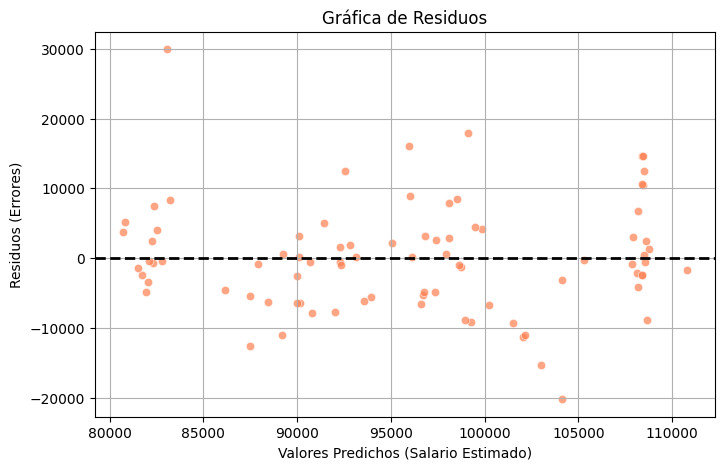

In [12]:
# 2. Gráfica de Errores Residuales (Residual Plot)
plt.figure(figsize=(8, 5))
sns.scatterplot(x=y_pred, y=residuos, color='coral', alpha=0.7)
plt.axhline(y=0, color='black', linestyle='--', lw=2)  # Línea en cero
plt.title('Gráfica de Residuos')
plt.xlabel('Valores Predichos (Salario Estimado)')
plt.ylabel('Residuos (Errores)')
plt.grid(True)
plt.show()

# 5. Evalúa el modelo

- Calcula el MSE del modelo construido. Recuerda que usas el propio conjunto de datos (No hablamos nada de entrenamiento y test).
- Calcula el R² Score

Discute estos resultados obtenidos.

In [13]:
from sklearn.metrics import mean_squared_error, r2_score

# Calcular las métricas de evaluación
mse = mean_squared_error(y, y_pred)
r2 = r2_score(y, y_pred)

print(f"--- Evaluación del Modelo ---")
print(f"Error Cuadrático Medio (MSE): {mse:.4f}")
print(f"Raíz del Error Cuadrático Medio (RMSE): {np.sqrt(mse):.4f}")
print(f"Coeficiente de Determinación (R² Score): {r2:.4f}")

--- Evaluación del Modelo ---
Error Cuadrático Medio (MSE): 60480269.1466
Raíz del Error Cuadrático Medio (RMSE): 7776.9061
Coeficiente de Determinación (R² Score): 0.5705


# 6. Realiza un análisis de varianza con stastmodel

Consulta esto aquí https://www.statsmodels.org/dev/examples/notebooks/generated/variance_components.html

In [14]:
import statsmodels.api as sm
from statsmodels.formula.api import ols

# Ajustamos el modelo usando la interfaz de fórmulas de statsmodels para facilitar el ANOVA
modelo_formula = ols('salary ~ cost + C(location)', data=df_selected).fit()

# Realizar el análisis de varianza tipo II
anova_table = sm.stats.anova_lm(modelo_formula, typ=2)

print("--- Tabla ANOVA ---")
display(anova_table)

--- Tabla ANOVA ---


,sum_sq,df,F,PR(>F)
C(location),4.071774e+09,3.0,21.121259,3.570975e-10
cost,7.878166e+08,1.0,12.259774,7.600629e-04
Residual,5.140823e+09,80.0,NaN,NaN
